In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

CSV_PATH = Path("../raw/airbus-ship-detection/train_ship_segmentations_v2.csv")


In [2]:
annotations = pd.read_csv(CSV_PATH)

labels = (
    annotations.assign(has_ship=annotations["EncodedPixels"].notna())
    .groupby("ImageId")["has_ship"]
    .any()
    .astype(int)
)

# All image IDs in the dataset
all_image_ids = labels.index.to_numpy()
all_labels = labels.to_numpy()

# Stratified sample so both classes are represented.
sample_ids, _, sample_labels, _ = train_test_split(
    all_image_ids,
    all_labels,
    train_size=4000,
    random_state=42,
    stratify=all_labels,
)

train_ids, val_ids = train_test_split(
    sample_ids,
    test_size=0.2,
    random_state=42,
    stratify=sample_labels,
)


In [3]:
# Keep the existing validation images excluded
val_id_set = set(val_ids)

full_train_ids = np.array(
    [image_id for image_id in all_image_ids if image_id not in val_id_set]
)

# Check the split
print("Total dataset images:", len(all_image_ids))
print("Validation images:", len(val_ids))
print("Training images:", len(full_train_ids))
print("Overlap with validation:", len(set(full_train_ids) & val_id_set))
print(
    "Training images containing ships:", int(labels.loc[full_train_ids].sum())
)
print(
    "Training images without ships:",
    len(full_train_ids) - int(labels.loc[full_train_ids].sum()),
)

Total dataset images: 192556
Validation images: 800
Training images: 191756
Overlap with validation: 0
Training images containing ships: 42379
Training images without ships: 149377


In [4]:
import torch
from PIL import Image, ImageFile
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF

ImageFile.LOAD_TRUNCATED_IMAGES = True
MASK_SIZE = 768
DATA_DIR = Path("../raw/airbus-ship-detection/train_v2")

In [5]:
def decode_rle(encoded_pixels, height=768, width=768):
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(encoded_pixels):
        return mask.reshape((height, width))

    values = np.asarray(
        encoded_pixels.split(),
        dtype=np.int64,
    )

    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths

    for start, end in zip(starts, ends):
        mask[start:end] = 1

    # Airbus RLE uses column-major order.
    return mask.reshape((width, height)).T

In [6]:
class AirbusSegmentationDataset(Dataset):
    def __init__(self, image_ids, annotations, image_dir, size=256):
        self.image_ids = list(image_ids)
        self.image_dir = Path(image_dir)
        self.size = size

        # Store only non-empty RLE masks, grouped by image.
        self.rle_by_image = (
            annotations.dropna(subset=["EncodedPixels"])
            .groupby("ImageId")["EncodedPixels"]
            .apply(list)
            .to_dict()
        )

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]

        with Image.open(self.image_dir / image_id) as img:
            image = img.convert("RGB")
            image.load()

        mask = np.zeros((MASK_SIZE, MASK_SIZE), dtype=np.uint8)

        for rle in self.rle_by_image.get(image_id, []):
            mask |= decode_rle(rle)

        # Resize image smoothly and mask with nearest-neighbor.
        image = TF.resize(
            image,
            [self.size, self.size],
            interpolation=InterpolationMode.BILINEAR,
        )

        mask = TF.resize(
            Image.fromarray(mask),
            [self.size, self.size],
            interpolation=InterpolationMode.NEAREST,
        )

        image = TF.to_tensor(image)
        image = TF.normalize(
            image,
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225),
        )

        mask = torch.from_numpy(np.array(mask, dtype=np.float32)).unsqueeze(0)

        return image, mask

In [7]:
train_seg_dataset = AirbusSegmentationDataset(
    full_train_ids, annotations, DATA_DIR, size=256
)

train_seg_loader = DataLoader(
    train_seg_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    drop_last=True,
)

print("Training images:", len(train_seg_dataset))
print("Batches per epoch:", len(train_seg_loader))
print("Batch size:", train_seg_loader.batch_size)

Training images: 191756
Batches per epoch: 11984
Batch size: 16


In [8]:
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
from torchvision.models import resnet18

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [9]:
class SimCLR(nn.Module):
    def __init__(self, projection_dim=128):
        super().__init__()

        backbone = resnet18(weights=None)

        # Replace the classification layer with an identity.
        feature_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()

        self.encoder = backbone

        self.projector = nn.Sequential(
            nn.Linear(feature_dim, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, projection_dim),
        )

    def forward(self, x):
        features = self.encoder(x)
        projections = self.projector(features)

        # Normalize projections for contrastive learning.
        projections = F.normalize(projections, dim=1)

        return features, projections


model = SimCLR().to(DEVICE)

In [10]:
class ResNet18Segmenter(nn.Module):
    def __init__(self, pretrained_encoder=None):
        super().__init__()

        backbone = resnet18(weights=None)

        if pretrained_encoder is not None:
            backbone.fc = nn.Identity()
            backbone.load_state_dict(pretrained_encoder.state_dict())

        self.stem = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu)

        self.maxpool = backbone.maxpool
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        def up_block(in_channels, out_channels):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_channels, out_channels, 3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
            )

        self.up4 = up_block(512 + 256, 256)
        self.up3 = up_block(256 + 128, 128)
        self.up2 = up_block(128 + 64, 64)
        self.up1 = up_block(64 + 64, 64)

        self.output = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):
        input_size = x.shape[-2:]

        x0 = self.stem(x)
        x1 = self.layer1(self.maxpool(x0))
        x2 = self.layer2(x1)
        x3 = self.layer3(x2)
        x4 = self.layer4(x3)

        d4 = F.interpolate(
            x4, size=x3.shape[-2:], mode="bilinear", align_corners=False
        )
        d4 = self.up4(torch.cat([d4, x3], dim=1))

        d3 = F.interpolate(
            d4, size=x2.shape[-2:], mode="bilinear", align_corners=False
        )
        d3 = self.up3(torch.cat([d3, x2], dim=1))

        d2 = F.interpolate(
            d3, size=x1.shape[-2:], mode="bilinear", align_corners=False
        )
        d2 = self.up2(torch.cat([d2, x1], dim=1))

        d1 = F.interpolate(
            d2, size=x0.shape[-2:], mode="bilinear", align_corners=False
        )
        d1 = self.up1(torch.cat([d1, x0], dim=1))

        logits = self.output(d1)

        return F.interpolate(
            logits, size=input_size, mode="bilinear", align_corners=False
        )


In [11]:
segmenter = ResNet18Segmenter(pretrained_encoder=model.encoder).to(DEVICE)
optimizer = AdamW(segmenter.parameters(), lr=1e-4, weight_decay=1e-4)

In [12]:
from pathlib import Path

checkpoint_dir = Path("../checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = checkpoint_dir / "varuna_segmentation_11k_baseline.pt"

torch.save(
    {
        "model_state_dict": segmenter.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "image_size": 256,
        "training_images": 11050,
        "threshold": 0.25,
        "validation_dice_025": 0.4080,
        "validation_iou_025": 0.2563,
        "validation_dice_050": 0.4700,
        "validation_iou_050": 0.3072,
    },
    checkpoint_path,
)

print(f"Checkpoint saved: {checkpoint_path.resolve()}")

Checkpoint saved: /home/abhi/Dev/varuna-ssl/checkpoints/varuna_segmentation_11k_baseline.pt


In [13]:
import time

segmenter.train()

running_loss = 0.0
start_time = time.time()
epoch_losses = []

In [14]:
def dice_loss(logits, targets, smooth=1.0):
    probabilities = torch.sigmoid(logits)

    probabilities = probabilities.flatten(start_dim=1)
    targets = targets.flatten(start_dim=1)

    intersection = (probabilities * targets).sum(dim=1)

    dice = (2 * intersection + smooth) / (
        probabilities.sum(dim=1) + targets.sum(dim=1) + smooth
    )

    return 1 - dice.mean()


In [15]:
def segmentation_loss(logits, masks):
    pos_weight = logits.new_tensor([10.0])

    bce = F.binary_cross_entropy_with_logits(
        logits, masks, pos_weight=pos_weight
    )

    dice = dice_loss(logits, masks)

    return bce + dice

In [16]:
for step, (images, masks) in enumerate(train_seg_loader, start=1):
    images = images.to(DEVICE)
    masks = masks.to(DEVICE)

    optimizer.zero_grad(set_to_none=True)

    logits = segmenter(images)
    loss = segmentation_loss(logits, masks)

    loss.backward()
    optimizer.step()

    running_loss += loss.item()

    if step % 200 == 0:
        avg_loss = running_loss / 200
        epoch_losses.append(avg_loss)

        elapsed = time.time() - start_time
        print(
            f"Batch {step}/{len(train_seg_loader)} | "
            f"Loss: {avg_loss:.4f} | "
            f"Elapsed: {elapsed / 60:.1f} min"
        )

        running_loss = 0.0

# Include the final partial interval in the history if needed
if len(train_seg_loader) % 200:
    remaining = len(train_seg_loader) % 200
    epoch_losses.append(running_loss / remaining)

print(
    f"\nFull epoch completed in {(time.time() - start_time) / 60:.2f} minutes"
)

Batch 200/11984 | Loss: 1.3785 | Elapsed: 0.5 min
Batch 400/11984 | Loss: 1.2347 | Elapsed: 0.9 min
Batch 600/11984 | Loss: 1.1656 | Elapsed: 1.4 min
Batch 800/11984 | Loss: 1.1153 | Elapsed: 1.8 min
Batch 1000/11984 | Loss: 1.0801 | Elapsed: 2.3 min
Batch 1200/11984 | Loss: 1.0557 | Elapsed: 2.7 min
Batch 1400/11984 | Loss: 1.0367 | Elapsed: 3.2 min
Batch 1600/11984 | Loss: 1.0132 | Elapsed: 3.6 min
Batch 1800/11984 | Loss: 1.0012 | Elapsed: 4.1 min
Batch 2000/11984 | Loss: 0.9870 | Elapsed: 4.5 min
Batch 2200/11984 | Loss: 0.9671 | Elapsed: 5.0 min
Batch 2400/11984 | Loss: 0.9615 | Elapsed: 5.4 min
Batch 2600/11984 | Loss: 0.9533 | Elapsed: 5.8 min
Batch 2800/11984 | Loss: 0.9443 | Elapsed: 6.3 min
Batch 3000/11984 | Loss: 0.9391 | Elapsed: 6.7 min
Batch 3200/11984 | Loss: 0.9347 | Elapsed: 7.2 min
Batch 3400/11984 | Loss: 0.9370 | Elapsed: 7.6 min
Batch 3600/11984 | Loss: 0.8784 | Elapsed: 8.1 min
Batch 3800/11984 | Loss: 0.8122 | Elapsed: 8.6 min
Batch 4000/11984 | Loss: 0.7321 | E

In [17]:
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

segmenter.eval()

results = {
    t: {"intersection": 0, "predicted": 0, "actual": 0} for t in thresholds
}
total_val_loss = 0.0
val_seg_dataset = AirbusSegmentationDataset(
    val_ids, annotations, DATA_DIR, size=256
)

val_seg_loader = DataLoader(
    val_seg_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
)

In [18]:
with torch.no_grad():
    for images, masks in val_seg_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE).bool()

        logits = segmenter(images)
        probabilities = torch.sigmoid(logits)

        total_val_loss += segmentation_loss(logits, masks.float()).item()

        for t in thresholds:
            predictions = probabilities > t
            r = results[t]

            r["intersection"] += (predictions & masks).sum().item()
            r["predicted"] += predictions.sum().item()
            r["actual"] += masks.sum().item()

print(f"Validation loss: {total_val_loss / len(val_seg_loader):.4f}\n")


Validation loss: 0.1915



In [19]:
for t in thresholds:
    r = results[t]
    intersection = r["intersection"]
    predicted = r["predicted"]
    actual = r["actual"]

    dice = (
        2 * intersection / (predicted + actual) if predicted + actual else 1.0
    )
    union = predicted + actual - intersection
    iou = intersection / union if union else 1.0

    print(
        f"Threshold {t:.2f} | Dice: {dice:.4f} | "
        f"IoU: {iou:.4f} | Predicted pixels: {predicted}"
    )

Threshold 0.10 | Dice: 0.5946 | IoU: 0.4231 | Predicted pixels: 75361
Threshold 0.15 | Dice: 0.6025 | IoU: 0.4311 | Predicted pixels: 71902
Threshold 0.20 | Dice: 0.6080 | IoU: 0.4368 | Predicted pixels: 69294
Threshold 0.25 | Dice: 0.6115 | IoU: 0.4404 | Predicted pixels: 67406
Threshold 0.30 | Dice: 0.6146 | IoU: 0.4437 | Predicted pixels: 65652
Threshold 0.40 | Dice: 0.6200 | IoU: 0.4492 | Predicted pixels: 62689
Threshold 0.50 | Dice: 0.6242 | IoU: 0.4537 | Predicted pixels: 60004


In [20]:
import matplotlib.pyplot as plt
import numpy as np

segmenter.eval()

# Find validation image IDs that contain ships
ship_ids = set(
    annotations.loc[annotations["EncodedPixels"].notna(), "ImageId"]
)
val_ship_ids = [image_id for image_id in val_ids if image_id in ship_ids]
ship_val_dataset = AirbusSegmentationDataset(
    val_ship_ids[:8], annotations, DATA_DIR, size=256
)
ship_val_loader = DataLoader(
    ship_val_dataset, batch_size=8, shuffle=False, num_workers=0
)

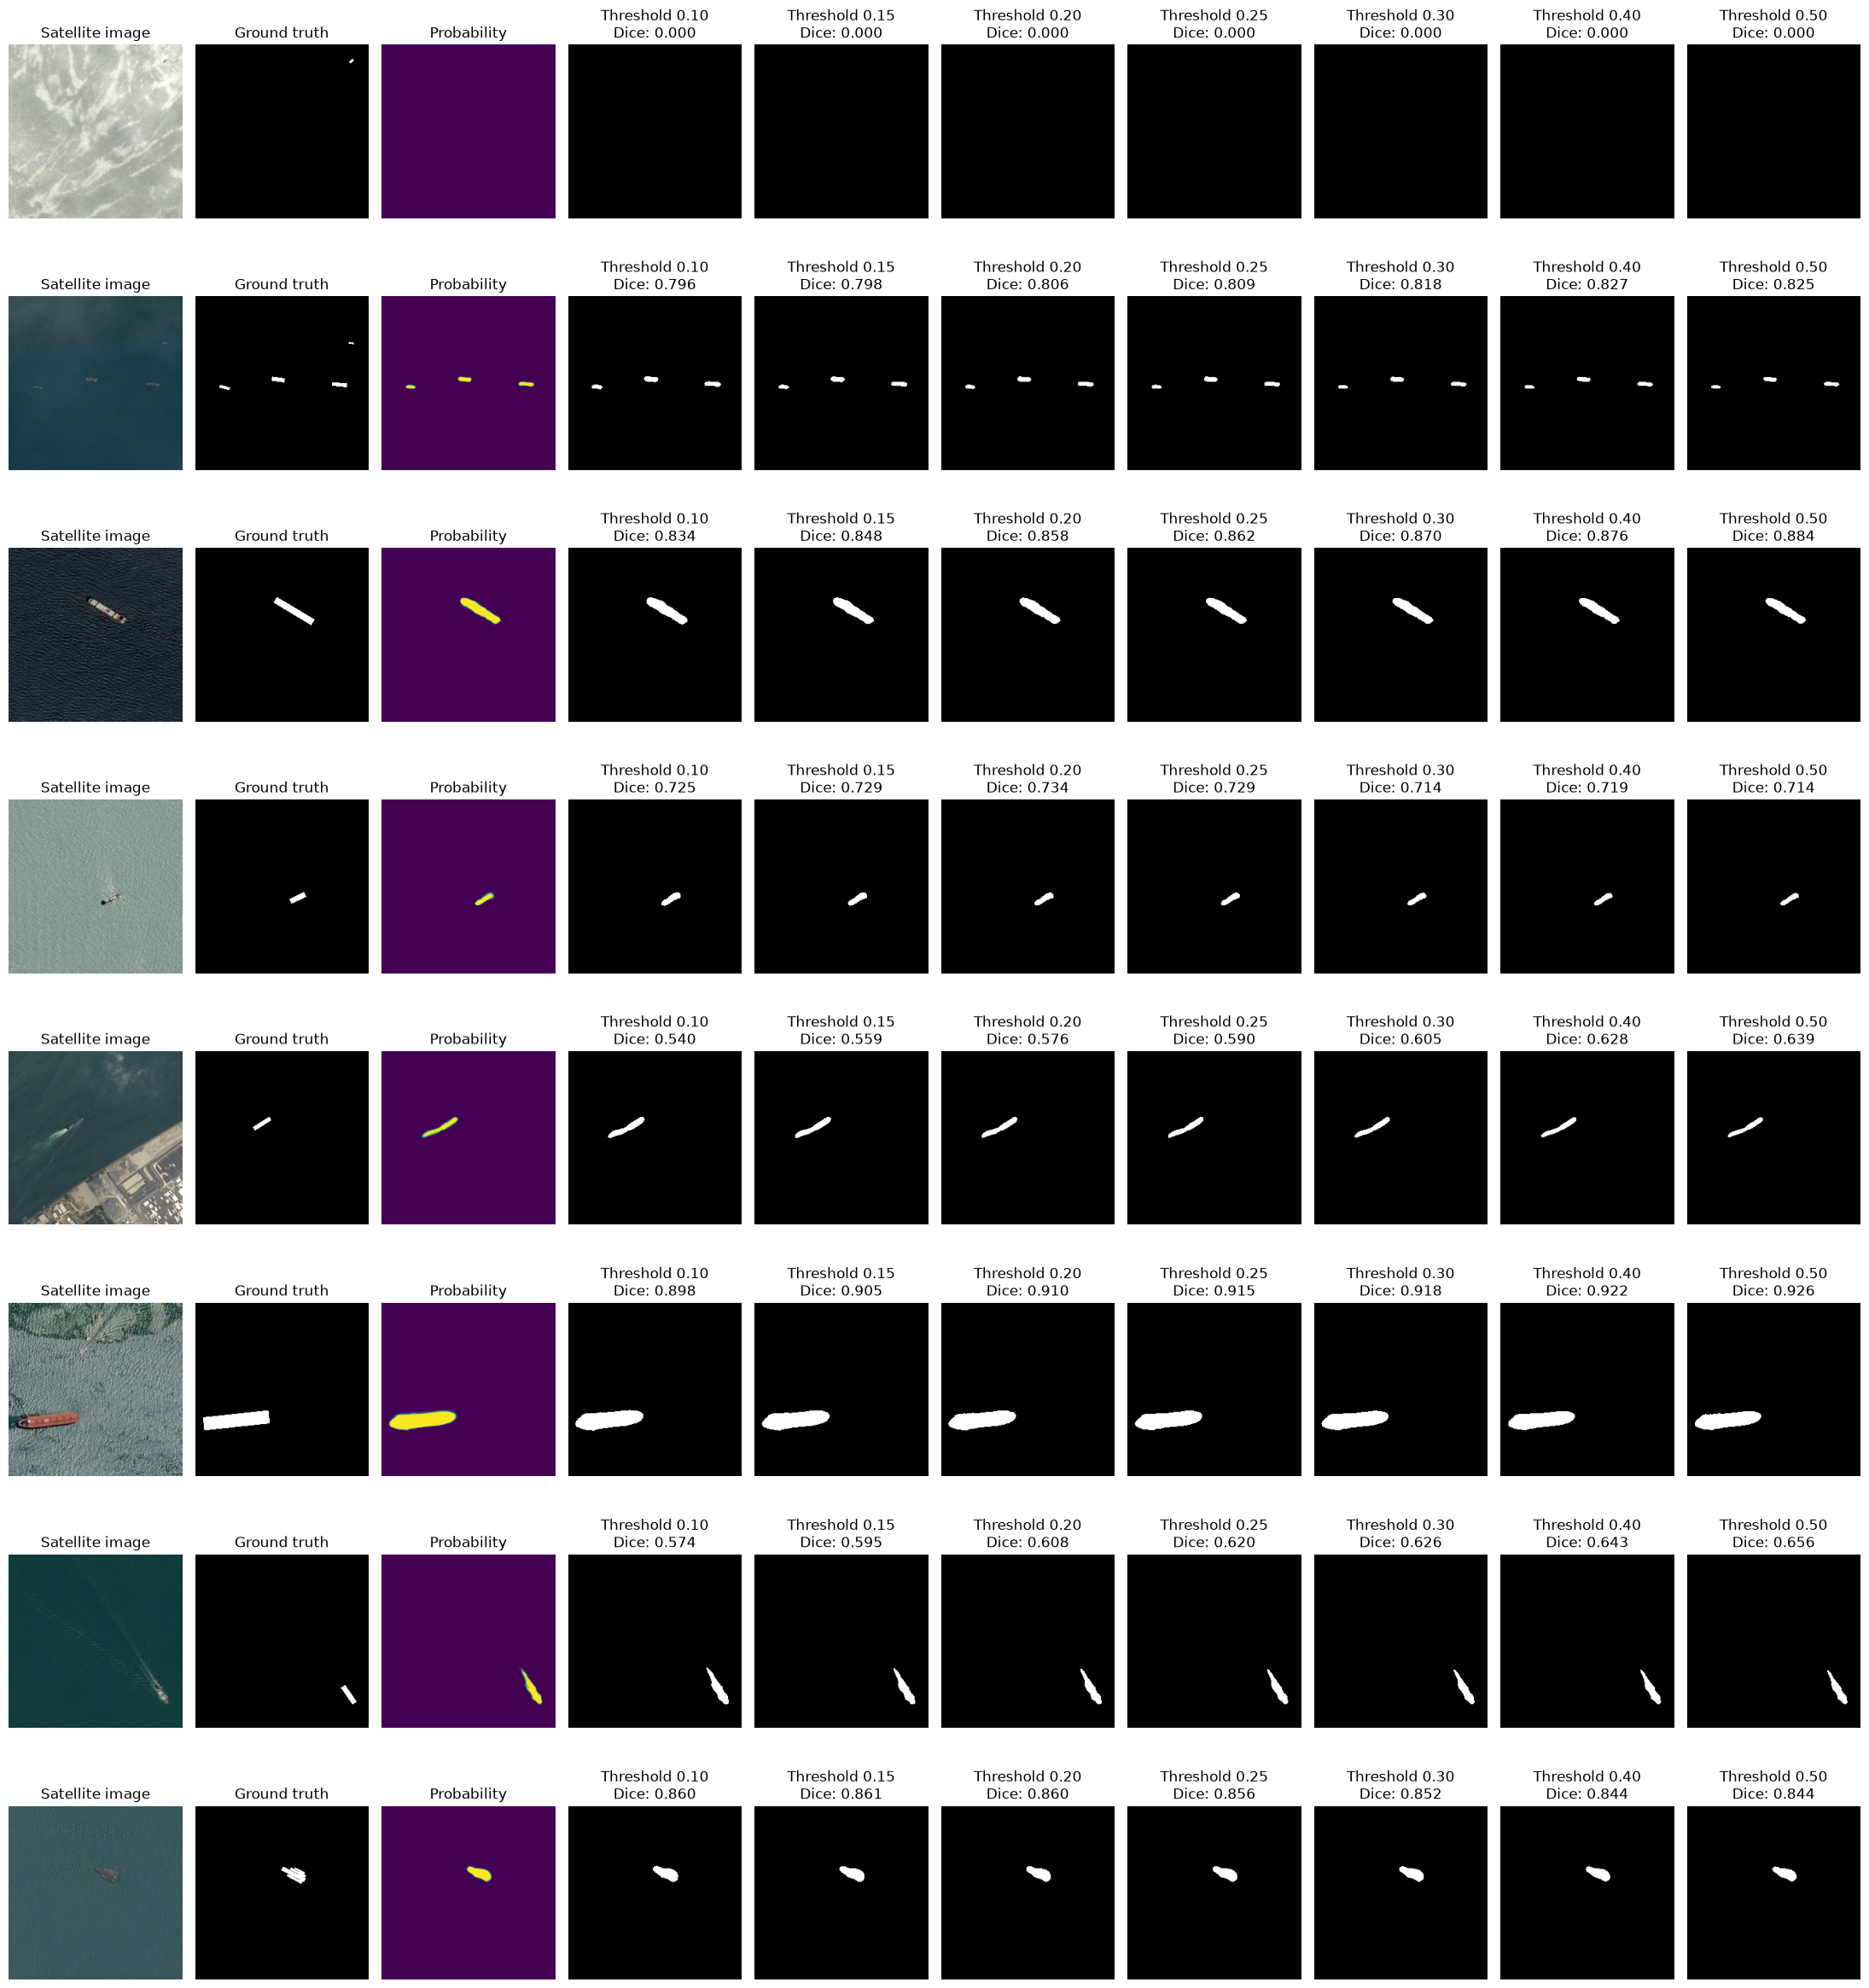

In [21]:
# Use ship-containing validation images
images, masks = next(iter(ship_val_loader))
images = images.to(DEVICE)
masks = masks.to(DEVICE)

with torch.no_grad():
    probabilities = torch.sigmoid(segmenter(images))

n = min(8, len(images))

fig, axes = plt.subplots(
    n, 3 + len(thresholds), figsize=(22, 3 * n), squeeze=False
)

for i in range(n):
    # Restore original image colors
    image = images[i].cpu().permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    image = np.clip(image * std + mean, 0, 1)

    truth = masks[i, 0].cpu().numpy() > 0.5
    prob = probabilities[i, 0].cpu().numpy()

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Satellite image")

    axes[i, 1].imshow(truth, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground truth")

    axes[i, 2].imshow(prob, cmap="viridis", vmin=0, vmax=1)
    axes[i, 2].set_title("Probability")

    for j, threshold in enumerate(thresholds):
        pred = prob > threshold

        intersection = np.logical_and(pred, truth).sum()
        denominator = pred.sum() + truth.sum()

        dice = 2 * intersection / denominator if denominator > 0 else 1.0

        ax = axes[i, j + 3]
        ax.imshow(pred, cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"Threshold {threshold:.2f}\nDice: {dice:.3f}")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [22]:
from pathlib import Path

RAW_DIR = Path("../raw/airbus-ship-detection")

list(RAW_DIR.iterdir())

[PosixPath('../raw/airbus-ship-detection/sample_submission_v2.csv'),
 PosixPath('../raw/airbus-ship-detection/test_v2'),
 PosixPath('../raw/airbus-ship-detection/train_ship_segmentations_v2.csv'),
 PosixPath('../raw/airbus-ship-detection/train_v2')]

In [23]:
from pathlib import Path

import torch

checkpoint_dir = Path("../checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": segmenter.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "threshold": 0.25,
        "image_size": 256,
        "training_images": len(full_train_ids),
        "epochs": 1,
    },
    checkpoint_dir / "varuna_segmentation_full_dataset_epoch1.pt",
)

print("Checkpoint saved.")

Checkpoint saved.


In [24]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

TEST_DIR = Path("../raw/airbus-ship-detection/test_v2")
IMAGE_SIZE = 256
THRESHOLD = 0.25
BATCH_SIZE = 32

test_images = sorted(TEST_DIR.glob("*.jpg"))
segmenter.eval()

candidates = []

In [25]:
for start in range(0, len(test_images), BATCH_SIZE):
    batch_paths = test_images[start : start + BATCH_SIZE]
    batch = []

    for path in batch_paths:
        with Image.open(path) as img:
            image = img.convert("RGB")
        image = TF.resize(
            image,
            [IMAGE_SIZE, IMAGE_SIZE],
            interpolation=InterpolationMode.BILINEAR,
        )
        image = TF.normalize(
            TF.to_tensor(image),
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225),
        )
        batch.append(image)

    inputs = torch.stack(batch).to(DEVICE)

    with torch.no_grad():
        probabilities = torch.sigmoid(segmenter(inputs))[:, 0]

    for i, prob in enumerate(probabilities.cpu().numpy()):
        mask = prob > THRESHOLD
        predicted_fraction = mask.mean()

        # Keep images with a non-trivial predicted foreground.
        if predicted_fraction > 0.0005:
            candidates.append(
                (
                    batch_paths[i],
                    float(prob.max()),
                    float(prob.mean()),
                    float(predicted_fraction),
                )
            )

    if (start // BATCH_SIZE + 1) % 100 == 0:
        print(
            f"Scanned {min(start + BATCH_SIZE, len(test_images)):,}"
            f" / {len(test_images):,} images"
        )

    if len(candidates) >= 100:
        break

candidates.sort(key=lambda x: x[3], reverse=True)

print("Candidate images:", len(candidates))
print("Top candidates:")
for path, max_prob, mean_prob, fraction in candidates[:10]:
    print(
        f"{path.name}: predicted foreground={fraction:.2%}, "
        f"max probability={max_prob:.3f}"
    )

Candidate images: 104
Top candidates:
033bc6b88.jpg: predicted foreground=4.65%, max probability=1.000
0b7359c38.jpg: predicted foreground=4.17%, max probability=1.000
08bd4cc90.jpg: predicted foreground=2.64%, max probability=1.000
082da365f.jpg: predicted foreground=2.59%, max probability=1.000
03e116ee7.jpg: predicted foreground=2.45%, max probability=0.995
009c7f8ec.jpg: predicted foreground=2.27%, max probability=1.000
00e90efc3.jpg: predicted foreground=2.27%, max probability=1.000
0677b2d96.jpg: predicted foreground=2.22%, max probability=0.999
01f13f599.jpg: predicted foreground=2.08%, max probability=1.000
0c0d90d8d.jpg: predicted foreground=1.98%, max probability=1.000


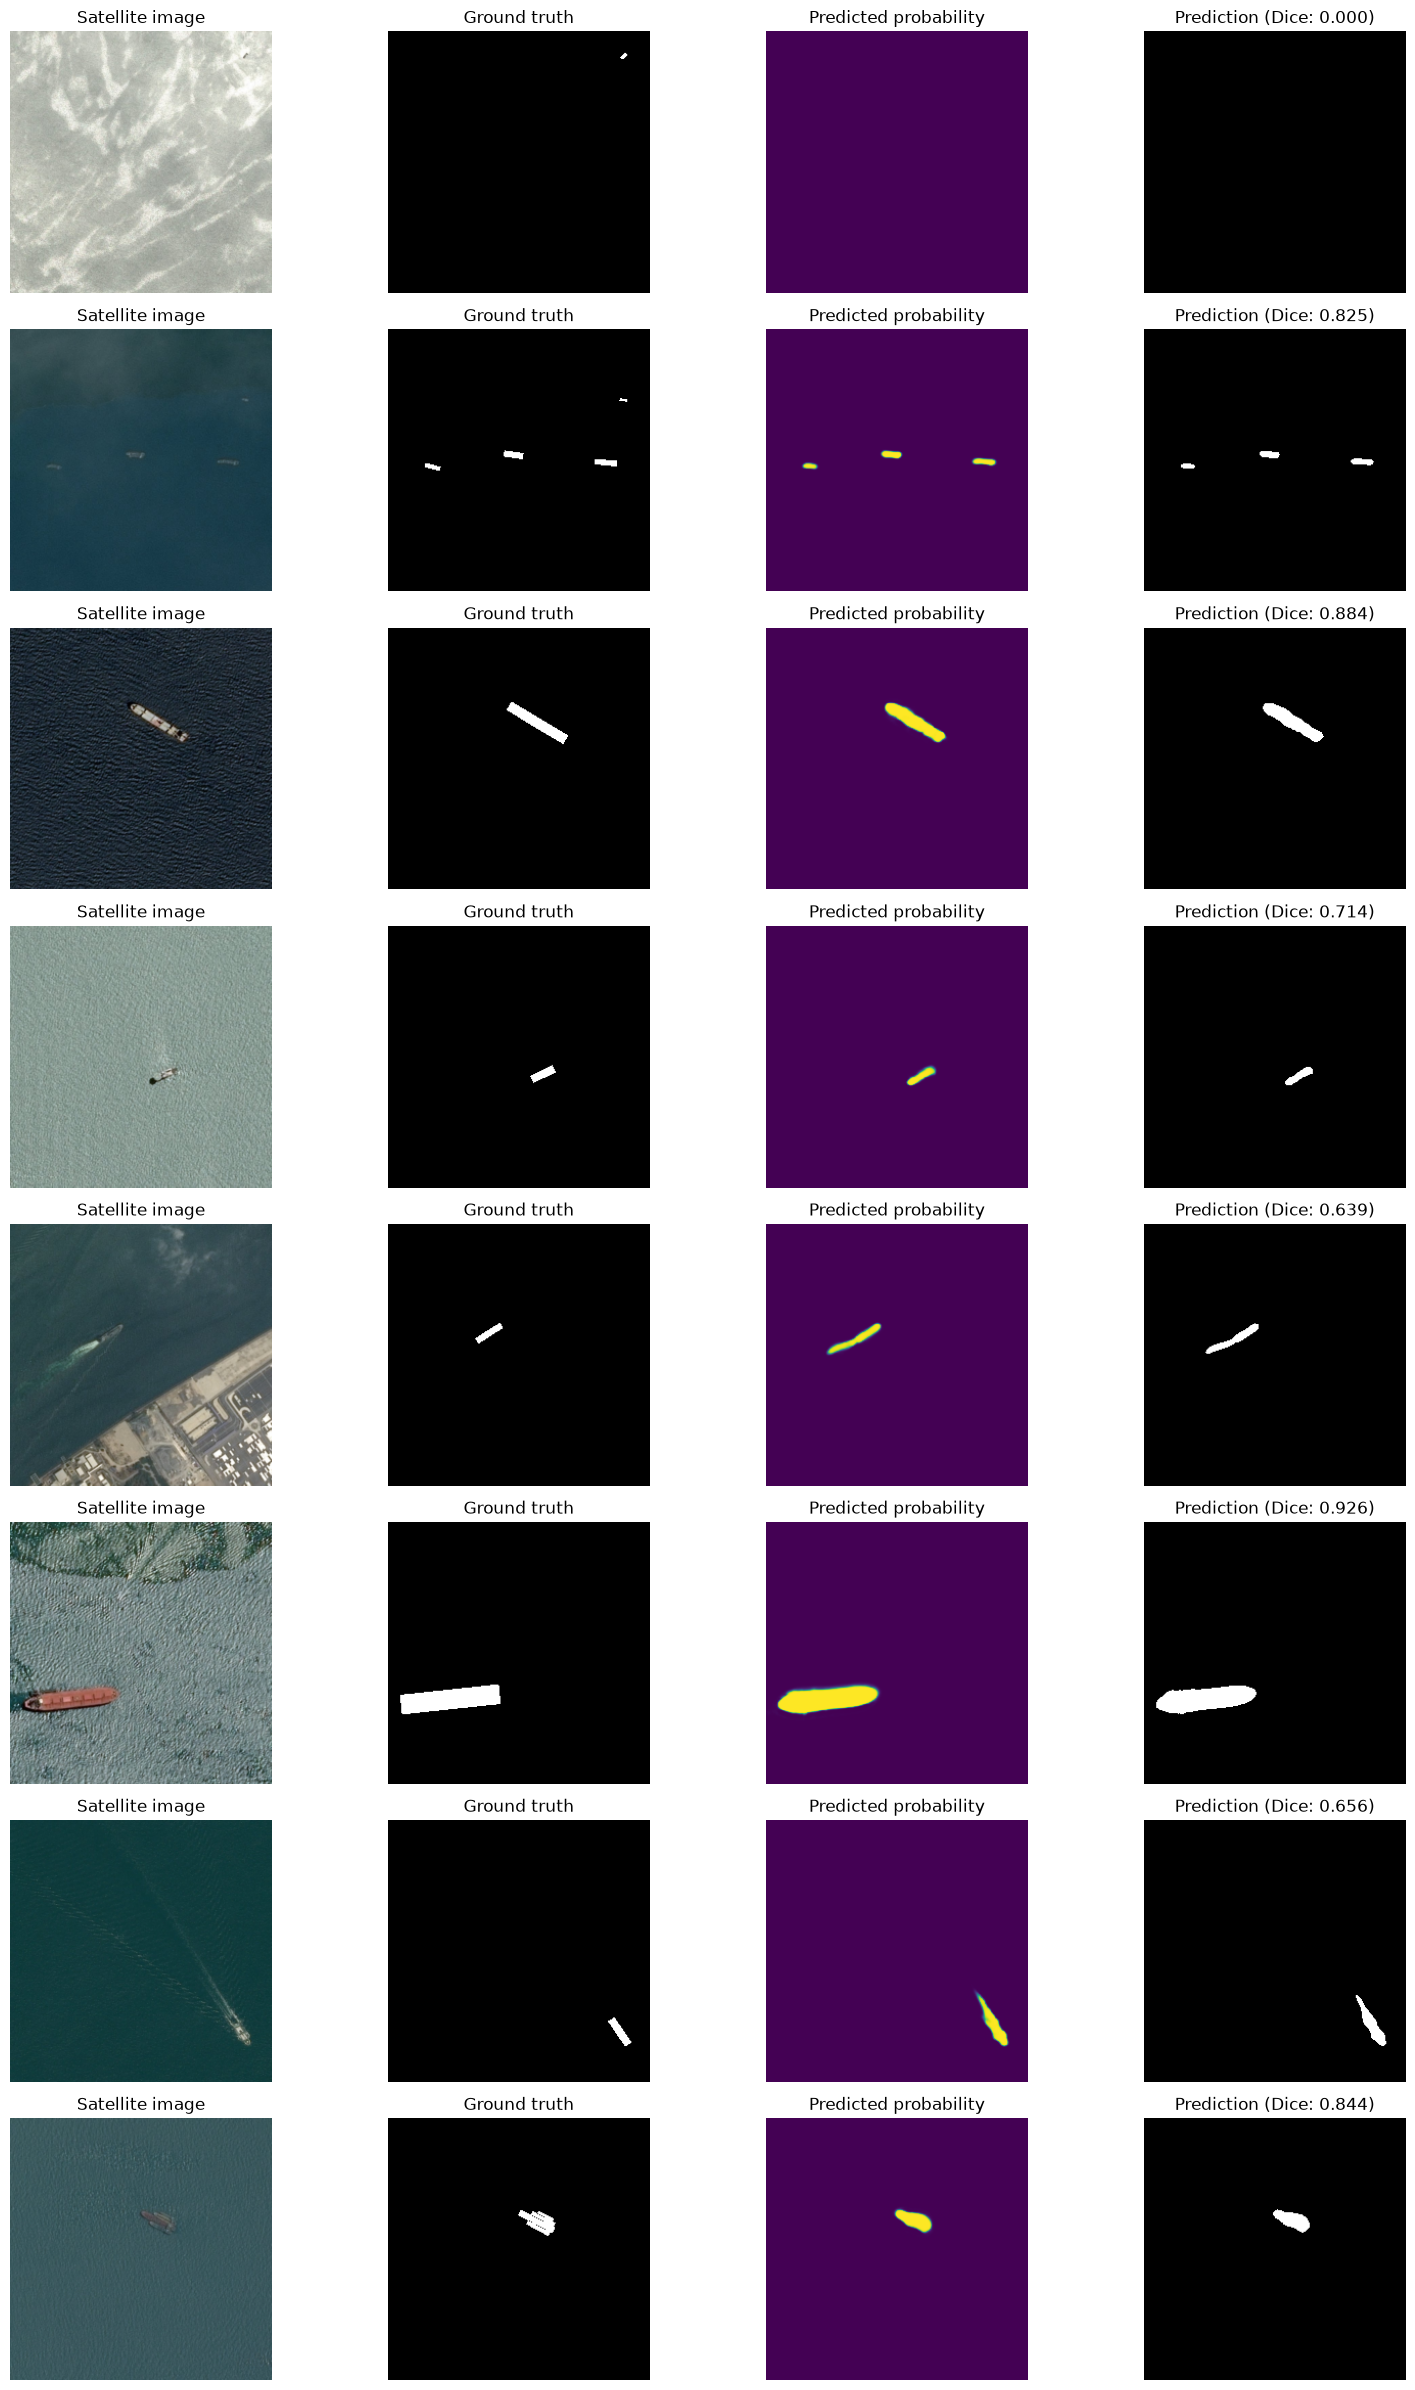

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import torch

THRESHOLD = 0.50

segmenter.eval()
images, masks = next(iter(ship_val_loader))

with torch.no_grad():
    probabilities = torch.sigmoid(segmenter(images.to(DEVICE))).cpu()

n = min(8, len(images))
fig, axes = plt.subplots(n, 4, figsize=(16, 3 * n), squeeze=False)

for i in range(n):
    # Undo ImageNet normalization
    image = images[i].cpu().permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    image = np.clip(image * std + mean, 0, 1)

    truth = masks[i, 0].numpy() > 0.5
    prob = probabilities[i, 0].numpy()
    pred = prob > THRESHOLD

    intersection = np.logical_and(pred, truth).sum()
    denominator = pred.sum() + truth.sum()
    dice = 2 * intersection / denominator if denominator else 1.0

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Satellite image")

    axes[i, 1].imshow(truth, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground truth")

    axes[i, 2].imshow(prob, cmap="viridis", vmin=0, vmax=1)
    axes[i, 2].set_title("Predicted probability")

    axes[i, 3].imshow(pred, cmap="gray", vmin=0, vmax=1)
    axes[i, 3].set_title(f"Prediction (Dice: {dice:.3f})")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [27]:
from pathlib import Path

import torch
from PIL import Image
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF

TEST_DIR = Path("../raw/airbus-ship-detection/test_v2")
THRESHOLD = 0.50
BATCH_SIZE = 32

test_images = sorted(TEST_DIR.glob("*.jpg"))

predicted_ship = []
predicted_no_ship = []

segmenter.eval()

for start in range(0, len(test_images), BATCH_SIZE):
    paths = test_images[start : start + BATCH_SIZE]
    batch = []

    for path in paths:
        with Image.open(path) as img:
            image = img.convert("RGB")

        image = TF.resize(
            image,
            [IMAGE_SIZE, IMAGE_SIZE],
            interpolation=InterpolationMode.BILINEAR,
        )
        image = TF.normalize(
            TF.to_tensor(image),
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225),
        )
        batch.append(image)

    inputs = torch.stack(batch).to(DEVICE)

    with torch.no_grad():
        probabilities = torch.sigmoid(segmenter(inputs))

    masks = probabilities[:, 0] > THRESHOLD
    pixel_counts = masks.flatten(1).sum(dim=1).cpu().tolist()

    for path, count in zip(paths, pixel_counts):
        if count > 0:
            predicted_ship.append((path, count))
        else:
            predicted_no_ship.append((path, count))

print("Predicted ship:", len(predicted_ship))
print("Predicted no ship:", len(predicted_no_ship))

Predicted ship: 2136
Predicted no ship: 13470


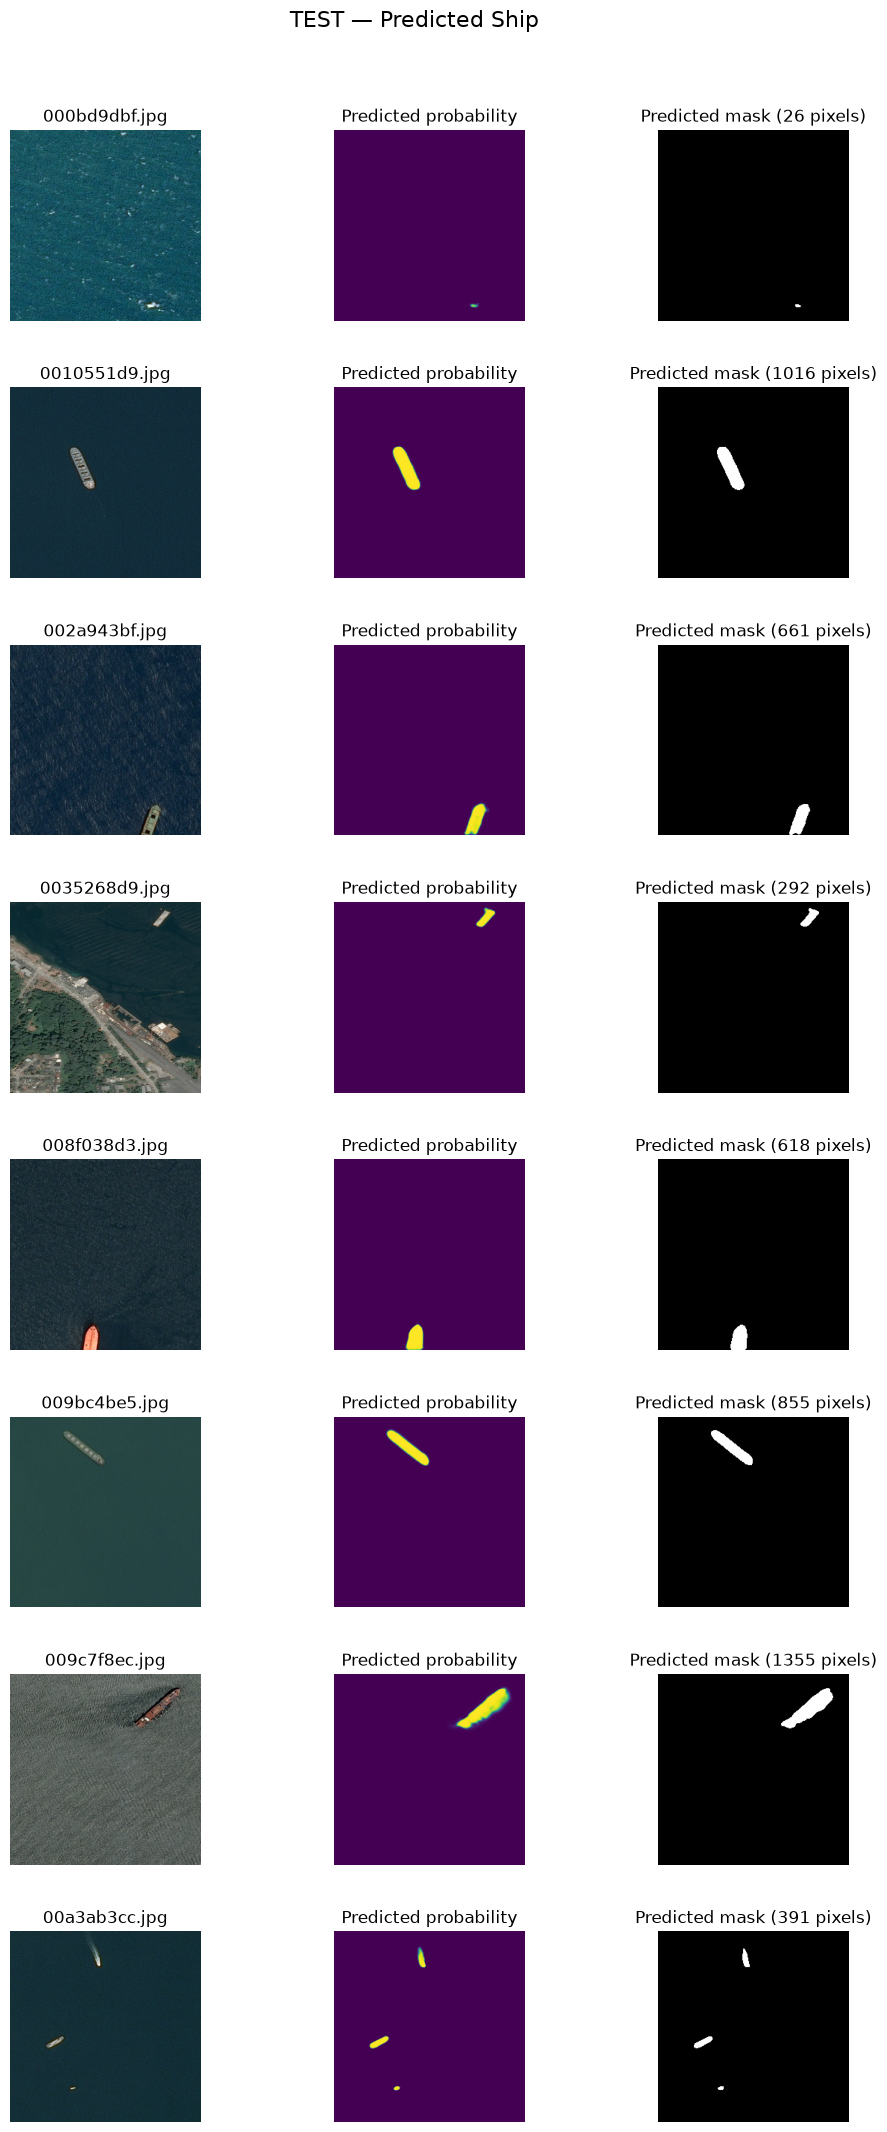

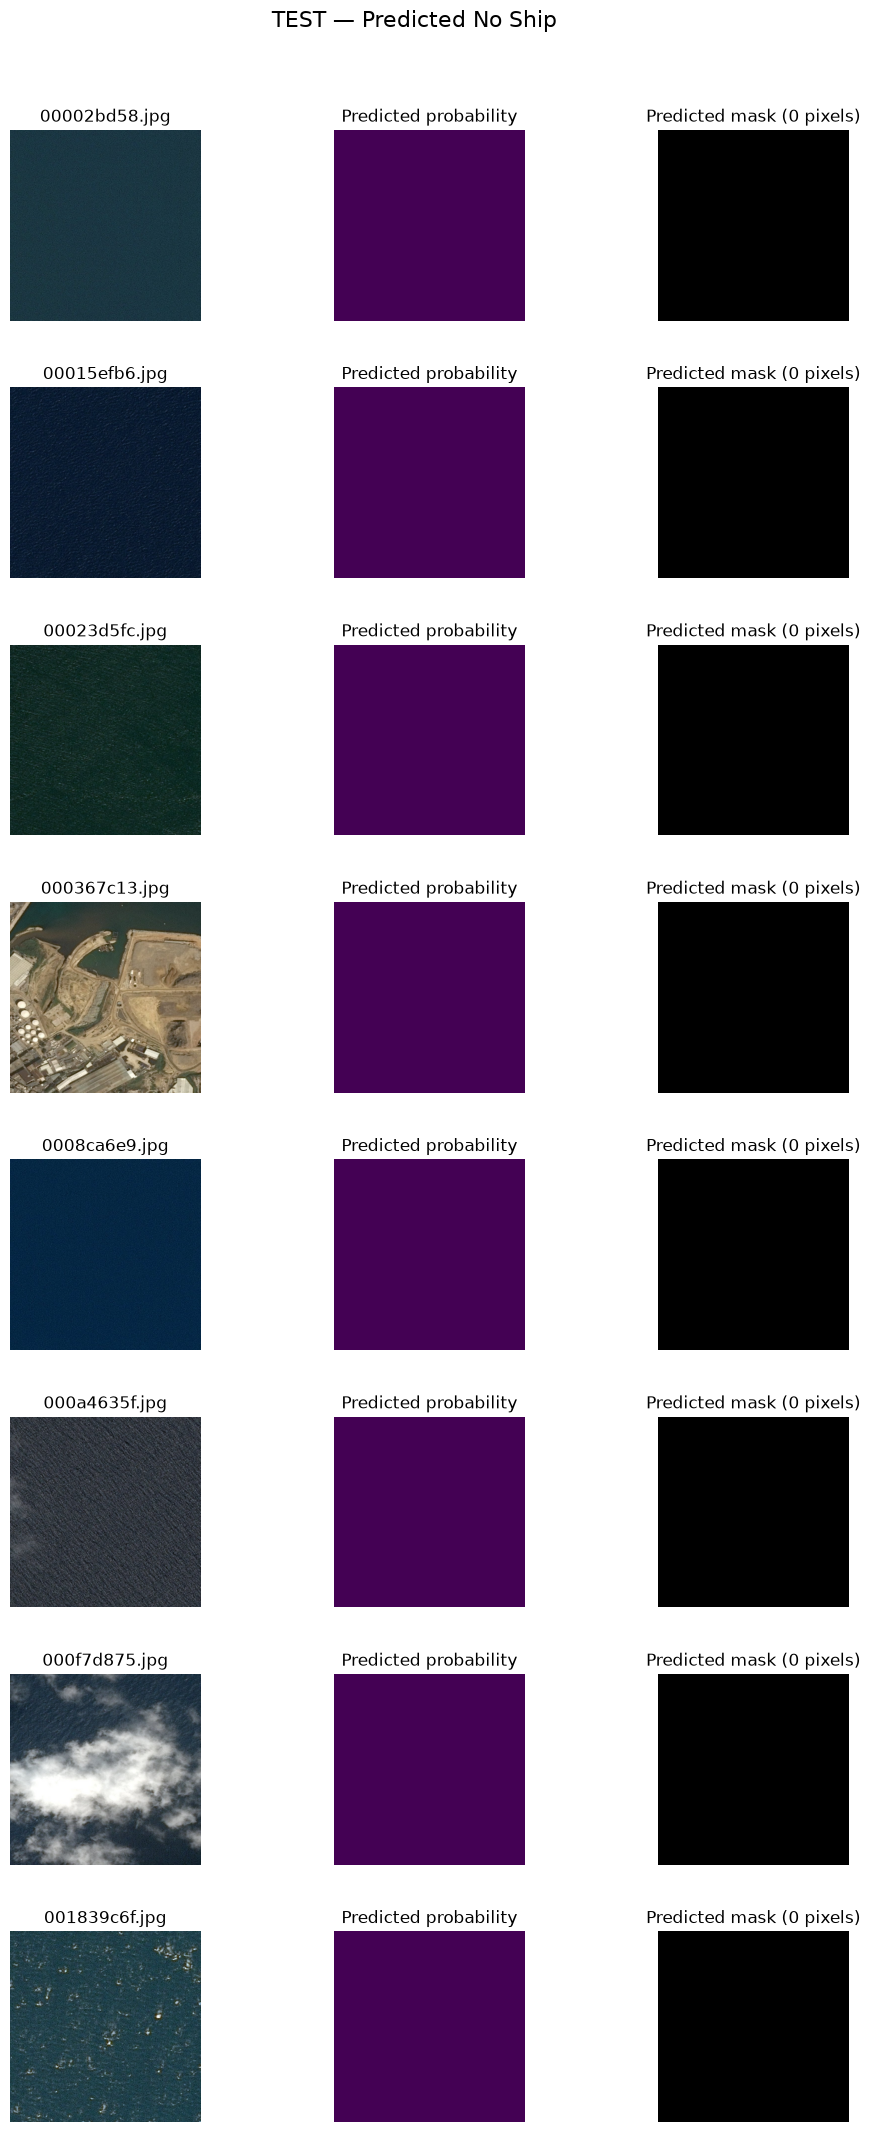

In [28]:
def show_examples(items, title, count=8):
    selected = items[:count]

    if not selected:
        print(f"No images in category: {title}")
        return

    fig, axes = plt.subplots(
        len(selected), 3, figsize=(12, 3 * len(selected)), squeeze=False
    )

    segmenter.eval()

    for i, (path, pixels) in enumerate(selected):
        with Image.open(path) as img:
            original = img.convert("RGB")

        image = TF.resize(
            original,
            [IMAGE_SIZE, IMAGE_SIZE],
            interpolation=InterpolationMode.BILINEAR,
        )

        image = (
            TF.normalize(
                TF.to_tensor(image),
                mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225),
            )
            .unsqueeze(0)
            .to(DEVICE)
        )

        with torch.no_grad():
            probability = torch.sigmoid(segmenter(image))[0, 0].cpu().numpy()

        mask = probability > THRESHOLD

        axes[i, 0].imshow(original)
        axes[i, 0].set_title(path.name)

        axes[i, 1].imshow(probability, cmap="viridis", vmin=0, vmax=1)
        axes[i, 1].set_title("Predicted probability")

        axes[i, 2].imshow(mask, cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title(f"Predicted mask ({mask.sum()} pixels)")

        for ax in axes[i]:
            ax.axis("off")

    fig.suptitle(title, fontsize=16, y=0.99)
    fig.subplots_adjust(top=0.94, hspace=0.35, wspace=0.15)
    plt.show()


show_examples(predicted_ship, "TEST — Predicted Ship")
show_examples(predicted_no_ship, "TEST — Predicted No Ship")